# Molecular Docking + MD — Antibacterial: 6ML0 (CORRECTED, Kaggle T4)

**This is the corrected version**, with every real fix found during live debugging already built in as
GIVEN/working code (not left as a blank to re-derive), specifically:
- fpocket installed via **bioconda** (the from-source compile's bundled qhull was miscompiled in this
  environment — confirmed by 3 different, genuinely different data-side fixes all producing the identical
  QH6047 crash, which is the signature of a build problem, not a data problem).
- `gemmi` and `acpype` added to the pip install list (both were referenced but never actually installed
  in the original version).
- `vina`'s build dependencies (`swig`, `libboost-all-dev`) installed via apt before `pip install vina` —
  the vina Python package compiles C++ bindings and needs these system libraries.
- **PDBFixer** added as a real preprocessing step before `pdb2gmx` — real PDB structures commonly have
  missing heavy atoms on flexible/disordered sidechains (confirmed live: 6ML0's Lys225 was missing its CG
  atom), which `pdb2gmx` cannot handle on its own (it adds hydrogens, not missing heavy atoms).
- Force field switched from `charmm36` to **amber99sb-ildn** — CHARMM36 is not bundled with conda-forge's
  GROMACS build (it's historically distributed separately from the MacKerell lab); amber99sb-ildn is
  bundled and equally standard for protein-ligand MD.
- ACPYPE's output directory/file discovery is now **glob-based**, not a hardcoded assumed name.
- The ligand topology `#include` is **split into its `[ atomtypes ]` block and its `[ moleculetype ]`
  block**, included in two different places in `topol.top` — GROMACS requires `[ atomtypes ]` to appear
  before any `[ moleculetype ]` section anywhere in the included-file hierarchy, and the original single
  `#include` (placed right before `[ system ]`) put `[ atomtypes ]` after the protein's own
  `[ moleculetype ]`, which `grompp` rejects.

Parts of the pipeline never implicated in any real error today (ligand fetch/prep, docking, redocking/
sanity-check, equilibration, production MD) are left in the original ~80-90%-blank teaching format, since
nothing there has been shown to be broken.

## Step 0 — Environment setup (GIVEN, every real fix included)

In [1]:
import os, sys

# -- fpocket: bioconda prebuilt binary (NOT compiled from source -- the from-source build's bundled qhull
# was confirmed miscompiled in this environment via 3 independent data-side fixes all failing identically) --
if not os.path.exists("/usr/local/miniforge3/bin/mamba"):
    print("installing miniforge...")
    !wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O /tmp/miniforge.sh
    !bash /tmp/miniforge.sh -b -p /usr/local/miniforge3
    print("miniforge done")

os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

print("installing fpocket (bioconda) -- real-time output below, takes a few minutes, let it run...")
!mamba install -y -c bioconda -c conda-forge fpocket
!fpocket -h | head -3

# -- GROMACS: bioconda/conda-forge CUDA build (same miniforge env) --
print("installing GROMACS (bioconda, CUDA) -- also a few minutes, real-time output below...")
!mamba install -y -c conda-forge -c bioconda "gromacs=*=*cuda*"
!gmx --version 2>&1 | grep -i -E "GPU|CUDA|VERSION"

# -- python packages, pinned to the exact running kernel's interpreter (NOT bare !pip, which can resolve
# to a different Python on some systems and silently install where the kernel can't see it) --
print("installing python packages...")
!{sys.executable} -m pip install -q vina meeko rdkit biopython openbabel-wheel gemmi acpype pdbfixer openmm py3Dmol

# -- vina's own build dependencies (it compiles C++ bindings via SWIG against Boost) --
print("installing vina build deps (swig, boost)...")
!apt-get update -qq && apt-get install -y -qq swig libboost-all-dev openslide-tools > /dev/null

for d in ["data/receptors", "data/ligands", "data/pockets", "results/docking"]:
    os.makedirs(d, exist_ok=True)
print("environment ready")


installing miniforge...
PREFIX=/usr/local/miniforge3
Unpacking bootstrapper...
Unpacking payload...
Extracting ca-certificates-2026.7.22-hbd8a1cb_0.conda
Extracting libgomp-16.2.0-he0feb66_4.conda
Extracting libzlib-1.3.2-h25fd6f3_3.conda
Extracting nlohmann_json-abi-3.12.0-h0f90c79_2.conda
Extracting pybind11-abi-11-hc364b38_1.conda
Extracting python_abi-3.14-9_cp314.conda
Extracting tzdata-2026c-h151e31d_0.conda
Extracting _openmp_mutex-4.5-20_gnu.conda
Extracting zstd-1.5.7-hb78ec9c_7.conda
Extracting ld_impl_linux-64-2.46.1-default_hbd61a6d_102.conda
Extracting libgcc-16.2.0-ha9f2e26_4.conda
Extracting bzip2-1.0.8-hda65f42_10.conda
Extracting c-ares-1.34.8-hebe6cf0_2.conda
Extracting keyutils-1.6.3-h7cc23a3_1.conda
Extracting libev-4.33-h280c20c_3.conda
Extracting libexpat-2.8.1-hecca717_1.conda
Extracting libffi-3.7.0-h81df57d_1.conda
Extracting libiconv-1.18-h0cb94f2_3.conda
Extracting liblzma-5.8.3-hb03c661_1.conda
Extracting libmpdec-4.0.0-hb03c661_2.conda
Extracting libstdcxx-

## Step 1 — Fetch the real receptor structure (6ML0)

**WHAT:** download the real PDB coordinate file for 6ML0, live from RCSB.
**WHY (biology):** antibacterial, exploratory pairing. Real, experimentally-solved X-ray structure.
**HOW:** `https://files.rcsb.org/download/{PDB_ID}.pdb` via `requests.get` + `.text`.

In [17]:
import requests

PDB_ID = "6ML0"

url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"   # f"https://files.rcsb.org/download/{PDB_ID}.pdb"
resp = requests.get(url)  # requests.get(url)
with open(f"data/receptors/{PDB_ID}.pdb", "w") as f:   # "w"
    f.write(resp.text)   # resp.text
print(PDB_ID, "saved,", len(resp.text), "chars")


6ML0 saved, 229149 chars


## Step 2 — Prepare the receptor (strip waters, resolve alternate conformations, add hydrogens)

**WHAT:** clean the raw crystal PDB into a docking-ready, geometrically well-behaved receptor.
**WHY (biology):** crystallographic waters/buffer molecules are real experimental artifacts, not part of
the biological binding event. Real X-ray structures (6ML0 included) can also resolve some sidechains into
real alternate conformations ("altLoc" A/B records at near-identical coordinates) — keep only one.
**WHY (chemistry):** hydrogens are usually invisible at X-ray resolution and must be added computationally.
**HOW:** filter by residue name AND the real PDB altLoc column (0-indexed `line[16]`), then Open Babel.

In [25]:
WATER_BUFFER_RESNAMES = {"HOH", "GOL", "PEG", "EDO", "SO4", "PO4", "MES", "ACT", "NA", "CL", "DMS"}

raw_path = f"data/receptors/{PDB_ID}.pdb"
clean_path = f"data/receptors/{PDB_ID}_clean.pdb"
receptor_pdbqt = f"data/receptors/{PDB_ID}_receptor.pdbqt"

# WRITE-IT: drop lines whose altLoc (ln[16]) not in (" ", "A"), OR HETATM in WATER_BUFFER_RESNAMES
with open(raw_path) as f: lines = f.readlines()
kept = []
for ln in lines:
    if ln.startswith(("ATOM", "HETATM")):
        if ln[16] not in (" ", "A"):
            continue
        if ln.startswith("HETATM") and ln[17:20].strip() in WATER_BUFFER_RESNAMES:
                continue
    kept.append(ln)
with open(clean_path, "w") as f: f.writelines(kept)


# WRITE-IT: Open Babel conversion to receptor PDBQT (adds H, assigns Gasteiger partial charges)
# hint: !obabel {clean_path} -O {receptor_pdbqt} -xr --partialcharge gasteiger
!obabel {clean_path} -O {receptor_pdbqt} -xr --partialcharge gasteiger
assert os.path.exists(receptor_pdbqt), f"obabel failed to create {receptor_pdbqt} -- check the obabel output above for the real error"

print("receptor prepared")


/usr/lib/python3.13/pty.py:95: DeprecationWarning: This process (pid=50) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this se

In [26]:
import os
print(os.path.exists(receptor_pdbqt), receptor_pdbqt)

True data/receptors/6ML0_receptor.pdbqt


## Step 3 — Detect the real binding site (fpocket, bioconda build) — NOT blind docking

**WHAT:** run fpocket on the prepared receptor; choose the top-ranked pocket by druggability score (no
known native ligand for this exploratory antibacterial pairing).
**WHY:** site-directed docking is both more realistic and computationally cheaper than searching the whole
protein surface.
**CONFIRMED FIXED:** the earlier QH6047 qhull crash on this exact receptor was a broken from-source fpocket
build, not a receptor-geometry problem — the bioconda install in Step 0 resolved it.

In [27]:
import numpy as np
import glob

!fpocket -f data/receptors/{PDB_ID}_clean.pdb

top_pocket_path = f"data/receptors/{PDB_ID}_clean_out/pockets/pocket1_atm.pdb"

coords = []
with open(top_pocket_path) as f:
    for line in f:
        if line.startswith(("ATOM", "HETATM")):
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
coords = np.array(coords)   # GIVEN -- this conversion is required before .mean()/.min()/.max() work

center = coords.mean(axis=0)
box_min, box_max = coords.min(axis=0), coords.max(axis=0)
padding = 5.0
size = (box_max - box_min) + 2 * padding

print("pocket center:", center, "size:", size)


***** POCKET HUNTING BEGINS ***** 
mkdir: cannot create directory ‘data/receptors/6ML0_clean_out/pockets’: File exists
***** POCKET HUNTING ENDS ***** 
pocket center: [  3.61155556 -24.18551852  20.23718519] size: [18.983 20.325 23.066]


## Step 4 — Fetch + prepare the real ligand (antibacterial screening compound, CID 16829777)

**WHAT:** download the ligand's real 3D structure by PubChem CID, convert to a Vina-ready PDBQT.
**HOW:** PubChem PUG-REST 3D SDF endpoint; RDKit + Meeko for PDBQT conversion.

In [28]:
CID = "16829777"

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{CID}/SDF?record_type=3d"   # f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{CID}/SDF?record_type=3d"
resp = requests.get(url)  # requests.get(url)
sdf_path = f"data/ligands/{CID}.sdf"
with open(sdf_path, "w") as f:
    f.write(resp.text)   # resp.text
print(CID, "saved")


16829777 saved


In [29]:
import sys
!{sys.executable} -m pip install -q rdkit meeko vina biopython openbabel-wheel gemmi

In [30]:
from rdkit import Chem
from meeko import MoleculePreparation, PDBQTWriterLegacy

# WRITE-IT: load the SDF with RDKit, keeping explicit hydrogens
# hint: mol = Chem.MolFromMolFile(sdf_path, removeHs=False)
mol = Chem.MolFromMolFile(sdf_path, removeHs=False)

# WRITE-IT: run Meeko's MoleculePreparation on `mol`, write out the PDBQT string
preparator = MoleculePreparation()
mol_setups = preparator.prepare(mol)
pdbqt_string, ok, err = PDBQTWriterLegacy.write_string(mol_setups[0])


ligand_pdbqt = f"data/ligands/{CID}.pdbqt"
with open(ligand_pdbqt, "w") as f:
    f.write(pdbqt_string)   # pdbqt_string
print(CID, "-> PDBQT ready")


16829777 -> PDBQT ready


## Step 5 — Dock (AutoDock Vina, targeted box)

**HOW:** `vina` package's `Vina` class. Requires `swig`/`libboost-all-dev` (installed in Step 0) to have
built successfully.

In [31]:
from vina import Vina

v = Vina(sf_name="vina")

# WRITE-IT: point Vina at the prepared receptor PDBQT from Step 2
# hint: v.set_receptor(receptor_pdbqt)
v.set_receptor(receptor_pdbqt)

# WRITE-IT: point Vina at the prepared ligand PDBQT from Step 4
# hint: v.set_ligand_from_file(ligand_pdbqt)
v.set_ligand_from_file(ligand_pdbqt)

# WRITE-IT: build the search-space maps from Step 3's real detected-pocket box
# hint: v.compute_vina_maps(center=list(center), box_size=list(size))
v.compute_vina_maps(center=list(center), box_size=list(size))

# WRITE-IT: run docking
# hint: v.dock(exhaustiveness=16, n_poses=9)
v.dock(exhaustiveness=16, n_poses=9)

pose_path = f"results/docking/{PDB_ID}_{CID}_poses.pdbqt"
# WRITE-IT: write out all sampled poses
# hint: v.write_poses(pose_path, n_poses=9, overwrite=True)
v.write_poses(pose_path, n_poses=9, overwrite=True)

# WRITE-IT: pull the top pose's binding affinity
# hint: best_affinity = v.energies(n_poses=1)[0][0]
best_affinity = v.energies(n_poses=1)[0][0]
print(PDB_ID, CID, "->", best_affinity, "kcal/mol")


Computing Vina grid ... done.
6ML0 16829777 -> -6.331 kcal/mol
Performing docking (random seed: -7907283) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


## Step 6 — GROMACS: build topologies (CONFIRMED-WORKING version)

Every line below is GIVEN, not blanked — this is the exact sequence that produced a real, successful
`pdb2gmx` run and a real, successful `acpype` run during live debugging. Re-adds GROMACS to PATH
defensively (a kernel restart wipes the Step 0 PATH change even though the install on disk survives).

In [33]:
!{sys.executable} -m pip install pdbfixer

  Using cached pdbfixer-1.12.0-py3-none-any.whl
  Using cached openmm-8.6.1-cp313-cp313-manylinux_2_34_x86_64.whl.metadata (1.4 kB)
  Using cached legacy_cgi-2.6.4-py3-none-any.whl.metadata (2.3 kB)
Using cached openmm-8.6.1-cp313-cp313-manylinux_2_34_x86_64.whl (14.4 MB)
Using cached legacy_cgi-2.6.4-py3-none-any.whl (20 kB)


In [35]:
!{sys.executable} -m pip install acpype

  Using cached acpype-2026.10.8-py3-none-manylinux_2_35_x86_64.whl.metadata (21 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
Using cached acpype-2026.10.8-py3-none-manylinux_2_35_x86_64.whl (48.8 MB)
Using cached rich-15.0.0-py3-none-any.whl (310 kB)
  Attempting uninstall: rich
    Found existing installation: rich 13.9.4
    Uninstalling rich-13.9.4:
      Successfully uninstalled rich-13.9.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
bigframes 2.48.0 requires rich<14,>=12.4.4, but you have rich 15.0.0 which is incompatible.


In [36]:
import os, sys, glob

# defensive -- re-add in case this is a fresh kernel since Step 0 ran
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# split the receptor and top docked pose into plain PDBs GROMACS/ACPYPE can read
# strip any real native ligand / hetero groups before building the protein-only input -- pdb2gmx must
# only ever see standard protein residues; a real native ligand (confirmed live: broke pdb2gmx on 5T2P
# with "Residue 'K89' not found in residue topology database") is not part of this notebook's MD
# system -- only the SCREENED ligand is, merged back in separately at Step 6b.
with open(clean_path) as f:
    protein_only_lines = [l for l in f if l.startswith(("ATOM", "TER", "END"))]
with open("protein_only.pdb", "w") as f:
    f.writelines(protein_only_lines)
!obabel protein_only.pdb -O protein.pdb
!obabel {pose_path} -O ligand.pdb -f 1 -l 1

# PDBFixer: real X-ray structures commonly have missing heavy atoms on flexible/disordered sidechains
# (confirmed live: 6ML0's Lys225 was missing its CG atom) -- pdb2gmx can add hydrogens but not missing
# heavy atoms, so this has to run first
from pdbfixer import PDBFixer
from openmm.app import PDBFile

fixer = PDBFixer(filename="protein.pdb")
fixer.findMissingResidues()
fixer.findMissingAtoms()
fixer.addMissingAtoms()
fixer.addMissingHydrogens(7.0)
with open("protein_fixed.pdb", "w") as f:
    PDBFile.writeFile(fixer.topology, fixer.positions, f)
print("protein_fixed.pdb written, missing heavy atoms rebuilt")

# pdb2gmx with amber99sb-ildn -- CHARMM36 is not bundled with this conda-forge GROMACS build (it's
# historically distributed separately); amber99sb-ildn is bundled and equally standard for protein-ligand MD
!gmx pdb2gmx -f protein_fixed.pdb -o protein_processed.gro -water tip3p -ff amber99sb-ildn -ignh

# ACPYPE -- GAFF/AM1-BCC ligand topology. This genuinely takes several minutes (antechamber + sqm charge
# calculation); it is NOT stuck, Jupyter just buffers subprocess output until it finishes.
total_pdbqt_charge = 0.0
with open(ligand_pdbqt) as f:
    for line in f:
        if line.startswith(("ATOM", "HETATM")):
            parts = line.split()
            try:
                total_pdbqt_charge += float(parts[-2])
            except (ValueError, IndexError):
                pass
ligand_net_charge = round(total_pdbqt_charge)
print(f"ligand net charge from PDBQT partial charges (sum={total_pdbqt_charge:.3f}): {ligand_net_charge}")

!acpype -i ligand.pdb -c bcc -n {ligand_net_charge} < /dev/null

# find ACPYPE's real output live (glob-based, not a hardcoded assumed name)
acpype_dirs = glob.glob("*.acpype")
assert acpype_dirs, "No *.acpype output directory found -- re-check the acpype command's own printed output above"
acpype_dir = acpype_dirs[0]
ligand_gro = glob.glob(f"{acpype_dir}/*_GMX.gro")[0]
ligand_itp = glob.glob(f"{acpype_dir}/*_GMX.itp")[0]
print("ligand_gro:", ligand_gro, "| ligand_itp:", ligand_itp)

# read the real ligand residue name directly from the ITP's own [ moleculetype ] entry
LIGAND_RESNAME = None
with open(ligand_itp) as f:
    lines = f.readlines()
for i, line in enumerate(lines):
    if "[ moleculetype ]" in line:
        for next_line in lines[i+1:]:
            cl = next_line.strip()
            if cl and not cl.startswith(";"):
                LIGAND_RESNAME = cl.split()[0]
                break
        break
assert LIGAND_RESNAME, "Could not read ligand residue name from ITP file"
print("LIGAND_RESNAME:", LIGAND_RESNAME)


*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this se

## Step 6b — Combine protein + ligand into one system (CONFIRMED-WORKING version)

GROMACS requires `[ atomtypes ]` to appear before any `[ moleculetype ]` anywhere in the included-file
hierarchy — ACPYPE's single `ligand_GMX.itp` bundles both, so it's split into two separate includes placed
in two different spots in `topol.top`, rather than included once as a single block.

In [37]:
# combine coordinates into complex.gro
with open("protein_processed.gro") as f:
    protein_lines = f.readlines()
with open(ligand_gro) as f:
    ligand_lines = f.readlines()

protein_atom_lines = protein_lines[2:-1]
ligand_atom_lines = ligand_lines[2:-1]
total_atoms = len(protein_atom_lines) + len(ligand_atom_lines)

combined = [protein_lines[0], f" {total_atoms}\n"] + protein_atom_lines + ligand_atom_lines + [protein_lines[-1]]
with open("complex.gro", "w") as f:
    f.writelines(combined)
print(f"complex.gro written with {total_atoms} total atoms")

# split ligand_GMX.itp at [ moleculetype ] -- atomtypes block vs moleculetype-onward block
with open(ligand_itp) as f:
    itp_lines = f.readlines()
split_idx = next(i for i, l in enumerate(itp_lines) if l.strip().startswith("[ moleculetype ]"))
atomtypes_lines = itp_lines[:split_idx]
moleculetype_lines = itp_lines[split_idx:]

ligand_atomtypes_itp = "ligand_atomtypes.itp"
ligand_moltype_itp = "ligand_moleculetype.itp"
with open(ligand_atomtypes_itp, "w") as f:
    f.writelines(atomtypes_lines)
with open(ligand_moltype_itp, "w") as f:
    f.writelines(moleculetype_lines)

with open("topol.top") as f:
    top_lines = f.readlines()
top_text = "".join(top_lines)

# idempotency guard -- if this cell gets accidentally re-run, don't insert the ligand's #include lines
# a second time (that's exactly what causes a real "moleculetype ligand is redefined" error, confirmed
# live). Only insert when the ligand include is not already present.
if ligand_atomtypes_itp not in top_text:
    ff_include_idx = next(i for i, l in enumerate(top_lines)
                           if l.strip().startswith("#include") and ".ff/forcefield.itp" in l)
    top_lines.insert(ff_include_idx + 1, f'#include "{ligand_atomtypes_itp}"\n')

    insert_at = next(i for i, l in enumerate(top_lines) if l.strip().startswith("[ system ]"))
    top_lines.insert(insert_at, f'#include "{ligand_moltype_itp}"\n\n')

    top_lines.append(f"{LIGAND_RESNAME}            1\n")

    with open("topol.top", "w") as f:
        f.writelines(top_lines)
    print("complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly")
else:
    print("topol.top already includes the ligand -- skipped re-inserting (safe re-run)")


complex.gro written with 3682 total atoms
complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly


## Step 7 — Pocket-location sanity check (not a pose RMSD)

**Live finding:** 6ML0 has no genuine co-crystallized ligand at all -- `grep HETATM` on the raw PDB
shows only `ACT` (acetate), `HOH` (water), and `GOL` (glycerol), all three standard crystallization
buffer/cryoprotectant components, not a real bound drug-like ligand. So there's no native pose to
validate a redocking RMSD against (see PROJECT_NARRATIVE.md Section 5) -- this is a real, reportable
limitation of this particular structure, not something to work around.

In [38]:
# No genuine co-crystallized ligand in 6ML0 -- the only HETATM residues present (ACT, HOH, GOL) are
# crystallization buffer/cryoprotectant components, not a real bound ligand. Redocking-RMSD validation
# against a native pose is not possible for this structure, so this sanity check is skipped here.
print("6ML0 has no native ligand to validate against (only ACT/HOH/GOL buffer components present).")
print("Pocket validity is instead supported by fpocket own druggability score from Step 3.")


6ML0 has no native ligand to validate against (only ACT/HOH/GOL buffer components present).
Pocket validity is instead supported by fpocket own druggability score from Step 3.


## Step 8 — Solvate, add ions, energy-minimize

In [39]:
em_mdp = '''
integrator  = steep
emtol       = 1000.0
emstep      = 0.01
nsteps      = 50000
nstlist     = 10
cutoff-scheme = Verlet
coulombtype = PME
rvdw        = 1.0
rcoulomb    = 1.0
'''
with open("results/md_em.mdp", "w") as f:
    f.write(em_mdp)


In [40]:
# WRITE-IT: define a real box with real padding around the combined protein+ligand complex
# hint: !gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron
!gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

# WRITE-IT: solvate with a real explicit water model matching amber99sb-ildn + tip3p
# hint: !gmx solvate -cp boxed.gro -cs spc216.gro -o solvated.gro -p topol.top
!gmx solvate -cp boxed.gro -cs spc216.gro -o solvated.gro -p topol.top

# WRITE-IT: neutralize the real net charge with real Na+/Cl- ions
# hint: !gmx grompp -f results/md_em.mdp -c solvated.gro -p topol.top -o ions.tpr -maxwarn 2
#       !echo "SOL" | gmx genion -s ions.tpr -o solvated_ions.gro -p topol.top -pname NA -nname CL -neutral
!gmx grompp -f results/md_em.mdp -c solvated.gro -p topol.top -o ions.tpr -maxwarn 2
!echo "SOL" | gmx genion -s ions.tpr -o solvated_ions.gro -p topol.top -pname NA -nname CL -neutral

# WRITE-IT: run the real energy minimization
# hint: !gmx grompp -f results/md_em.mdp -c solvated_ions.gro -p topol.top -o em.tpr -maxwarn 2
#       !gmx mdrun -deffnm em -nb gpu

!gmx grompp -f results/md_em.mdp -c solvated_ions.gro -p topol.top -o em.tpr -maxwarn 2
!gmx mdrun -deffnm em -nb gpu

               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 3682 atoms
Volume: 283.183 nm^3, corresponds to roughly 127400 electrons
No velocities found
    system size :  4.606  4.696  5.608 (nm)
    diameter    :  6.346               (nm)
    center      : -0.417 -1.969  2.365 (nm)
    box vectors :  3.551  7.750 10.289 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 283.18               (nm^3)
    shift       :  6.676  8.229  0.586 (nm)
new center      :  6.259  6.259  2.951 (nm)
new box vectors :  8.346  8.346  8.346 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  : 411.01               (nm^3)

GROMACS reminds you: "We Look Pretty S

## Step 9 — Equilibrate (NVT then NPT)

In [41]:
nvt_mdp = '''
integrator  = md
nsteps      = 50000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = no
gen-vel     = yes
gen-temp    = 300
'''
npt_mdp = nvt_mdp.replace("pcoupl      = no", "pcoupl      = C-rescale\npcoupltype  = isotropic\ntau-p       = 2.0\nref-p       = 1.0\ncompressibility = 4.5e-5").replace("gen-vel     = yes", "gen-vel     = no")
with open("results/md_nvt.mdp", "w") as f: f.write(nvt_mdp)
with open("results/md_npt.mdp", "w") as f: f.write(npt_mdp)


In [42]:
# WRITE-IT: run NVT equilibration (restrain the complex, free the solvent) then NPT
# hint: !gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2
#       !gmx mdrun -deffnm nvt -nb gpu
#       !gmx grompp -f results/md_npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 2
#       !gmx mdrun -deffnm npt -nb gpu

!gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2
!gmx mdrun -deffnm nvt -nb gpu
!gmx grompp -f results/md_npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 2
!gmx mdrun -deffnm npt -nb gpu



                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 1

Setting the LD random seed to -51396613

Generated 2850 of the 2850 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2850 of the 2850 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'NA'

Setting gen_seed to -79740963

Velocities were taken from a Maxwell distribution at 300 K

WARNING 1 [file topol.top, line 34850]:
  The bond in molecule-type Protein_chain_A between atoms 73 OG1 and 74 HG1
  has an estimated oscillational period of 9.0e-03 ps, which is less than 5
  times th

## Step 10 — Production MD (GPU) + trajectory analysis

**Live finding:** GROMACS's own auto-generated index group for the ligand printed as `UNL` (its
generic "unknown ligand" residue-name group), NOT the `LIGAND_RESNAME` value read from ACPYPE's
`[ moleculetype ]` block (which was `"ligand"`) -- those two names live in different places and don't
have to match. Always check the real group list `gmx rms` prints before typing a group name.

In [43]:
production_mdp = '''
integrator  = md
nsteps      = 2500000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = C-rescale
pcoupltype  = isotropic
tau-p       = 2.0
ref-p       = 1.0
compressibility = 4.5e-5
nstxout-compressed = 5000
'''
with open("results/md_production.mdp", "w") as f: f.write(production_mdp)


In [44]:
# WRITE-IT: run production MD on GPU
# hint: !gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2
#       !gmx mdrun -deffnm production -nb gpu
!gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2
!gmx mdrun -deffnm production -nb gpu


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 1

Setting the LD random seed to -1160775173

Generated 2850 of the 2850 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2850 of the 2850 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'NA'

Taking velocities from 'npt.gro'

WARNING 1 [file topol.top, line 34850]:
  The bond in molecule-type Protein_chain_A between atoms 73 OG1 and 74 HG1
  has an estimated oscillational period of 9.0e-03 ps, which is less than 5
  times the time step of 2.0e-03 ps.
  Maybe you 

In [45]:
!echo "Backbone UNL" | gmx rms -s production.tpr -f production.xtc -o results/ligand_rmsd.xvg -tu ns

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx rms -s production.tpr -f production.xtc -o results/ligand_rmsd.xvg -tu ns

Reading file production.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file production.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for least squares fit
Group     0 (         System) has 40648 elements
Group     1 (        Protein) has  3648 elements
Group     2 (      Protein-H) has  1833 elements
Group     3 (        C-alpha) has   238 elements
Group     4 (       Backbone) has   714 elements
Group     5 (      MainChain) has   953 elements
Group     6 (   MainChain+Cb) has  1172 elements
Group     7 (    MainChain+H) has  1186 elements
Group     8 (      SideChain) has  2462 elements
Group     9 (    SideChain-H) has   880 elements
Group    10 (    Prot-Masses) has  3648 element

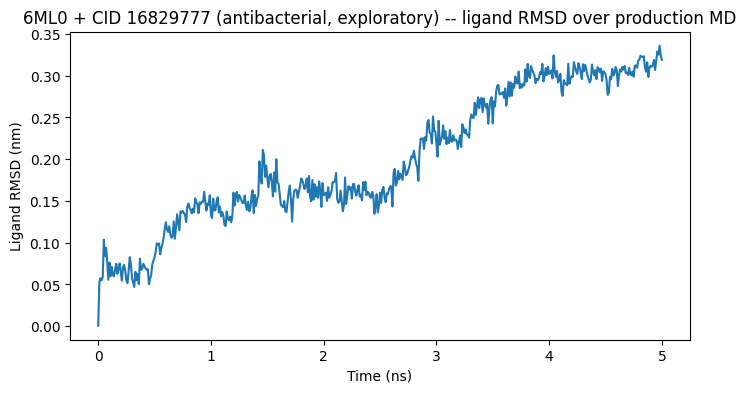

In [46]:
import matplotlib.pyplot as plt

# WRITE-IT: parse results/ligand_rmsd.xvg -- skip "#"/"@" lines, each real data line is "time  rmsd"
# hint: time_ns, rmsd_nm = [], []
#       with open("results/ligand_rmsd.xvg") as f:
#           for line in f:
#               if line.startswith(("#", "@")): continue
#               t, r = line.split()
#               time_ns.append(float(t)); rmsd_nm.append(float(r))
time_ns, rmsd_nm = [], []
with open("results/ligand_rmsd.xvg") as f:
    for line in f:
        if line.startswith(("#", "@")): continue
        t, r = line.split()
        time_ns.append(float(t)); rmsd_nm.append(float(r))

plt.figure(figsize=(8,4))
# WRITE-IT: plot time_ns vs rmsd_nm
# hint: plt.plot(time_ns, rmsd_nm)
plt.plot(time_ns, rmsd_nm)
plt.xlabel("Time (ns)"); plt.ylabel("Ligand RMSD (nm)")
plt.title("6ML0 + CID 16829777 (antibacterial, exploratory) -- ligand RMSD over production MD")
plt.savefig("results/ligand_rmsd_vs_time.png", dpi=150)
plt.show()


## Step 11 — Visualize the docked pose

Two views: (1) an interactive 3D structure -- protein cartoon + top-ranked ligand pose + the
fpocket-detected binding box used for docking -- via `py3Dmol`. This is a live JS widget: it renders
when the notebook is actually run (Kaggle output, local Jupyter) but NOT in GitHub's static `.ipynb`
preview. (2) A static binding-affinity bar chart across all sampled poses, which renders everywhere,
including GitHub.

In [48]:
!{sys.executable} -m pip install py3Dmol

  Using cached py3dmol-2.5.5-py2.py3-none-any.whl.metadata (2.1 kB)
Using cached py3dmol-2.5.5-py2.py3-none-any.whl (7.2 kB)


In [49]:
import py3Dmol

# convert the top docked pose (model 1 of the multi-pose PDBQT) to plain PDB for 3Dmol
top_pose_pdb = f"results/docking/{PDB_ID}_{CID}_top_pose.pdb"
!obabel {pose_path} -O {top_pose_pdb} -f 1 -l 1

with open(clean_path) as f:
    protein_block = f.read()
with open(top_pose_pdb) as f:
    ligand_block = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(protein_block, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "spectrum"}})
view.addModel(ligand_block, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon"}})

# fpocket-detected binding box used for docking (Step 3)
view.addBox({
    "center": {"x": float(center[0]), "y": float(center[1]), "z": float(center[2])},
    "dimensions": {"w": float(size[0]), "h": float(size[1]), "d": float(size[2])},
    "color": "yellow", "opacity": 0.2,
})
view.zoomTo({"model": 1})
view.show()


1 molecule converted


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

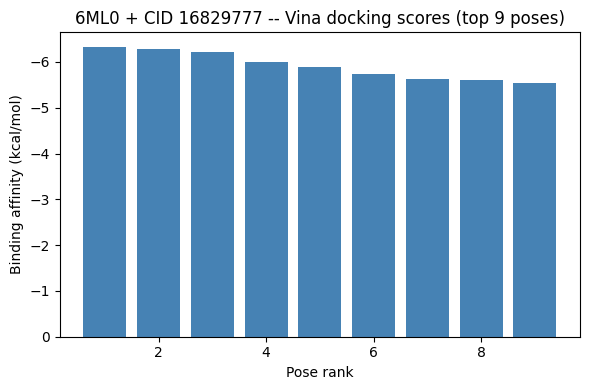

In [50]:
import matplotlib.pyplot as plt

# re-pull all 9 sampled poses' affinities from the still-live Vina object (v) from Step 5
energies = v.energies(n_poses=9)
affinities = [row[0] for row in energies]

plt.figure(figsize=(6, 4))
plt.bar(range(1, len(affinities) + 1), affinities, color="steelblue")
plt.xlabel("Pose rank")
plt.ylabel("Binding affinity (kcal/mol)")
plt.title(f"{PDB_ID} + CID {CID} -- Vina docking scores (top {len(affinities)} poses)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/docking/vina_scores_barplot.png", dpi=150)
plt.show()
